The Problem Statement

Traditional insurance pricing tables often rely on rigid, manual categories that overlook complex interactions between health risks (such as the combined impact of high Body Mass Index [BMI] and smoking habits). The organization needs an automated, data-driven framework to uncover hidden trends, estimate individual financial liability accurately, and ensure stable profit margins.

In [162]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Load insurance.csv
df = pd.read_csv(r"C:\Users\fiyre\Downloads\insurance.csv")

In [163]:
# Display first 5 rows
df.head()

,age,sex,bmi,children,smoker,region,charges,no,yes
0,19,1,27.900,0,1,southwest,16884.92400,0,1
1,18,0,33.770,1,0,southeast,1725.55230,0,1
2,28,0,33.000,3,0,southeast,4449.46200,0,1
3,33,0,22.705,0,0,northwest,21984.47061,0,1
4,32,0,28.880,0,0,northwest,3866.85520,0,1


In [ ]:
# Check dataset shape
df.shape

(1338, 7)

In [ ]:
# Check column names
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

In [ ]:
# Check data types
df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [12]:
# Check missing values
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [13]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [14]:
df["smoker"].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [15]:
df["sex"].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [17]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

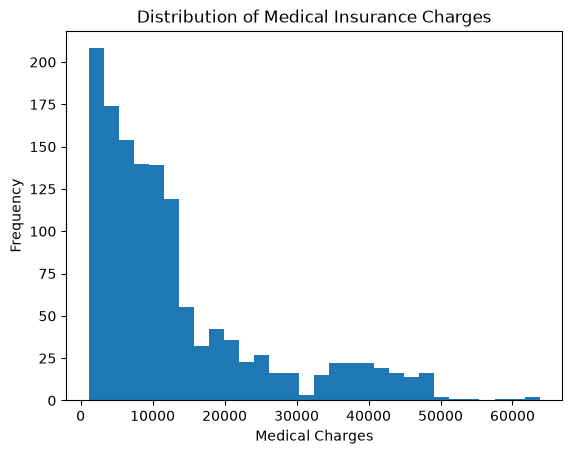

In [19]:
import matplotlib.pyplot as plt

plt.hist(df["charges"] , bins=30)
plt.xlabel("Medical Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Medical Insurance Charges")
plt.show()

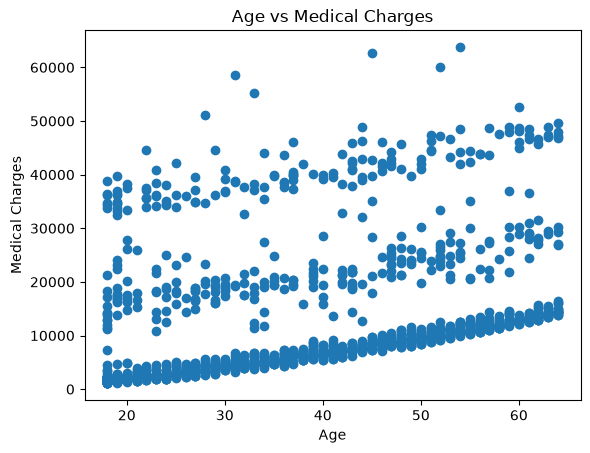

In [20]:
plt.scatter(df["age"], df["charges"])

plt.xlabel("Age")
plt.ylabel("Medical Charges")
plt.title("Age vs Medical Charges")

plt.show()

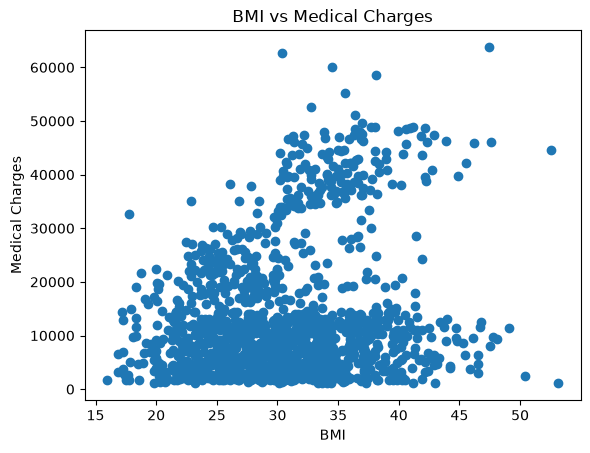

In [21]:
plt.scatter(df["bmi"], df["charges"])

plt.xlabel("BMI")
plt.ylabel("Medical Charges")
plt.title("BMI vs Medical Charges")

plt.show()

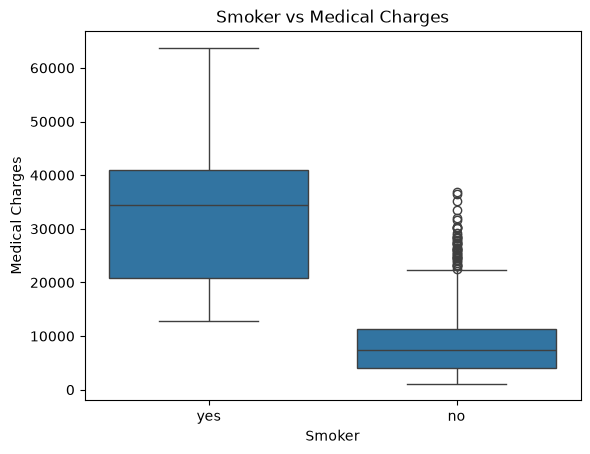

In [22]:
import seaborn as sns

sns.boxplot(x="smoker", y="charges", data=df)

plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.title("Smoker vs Medical Charges")

plt.show()

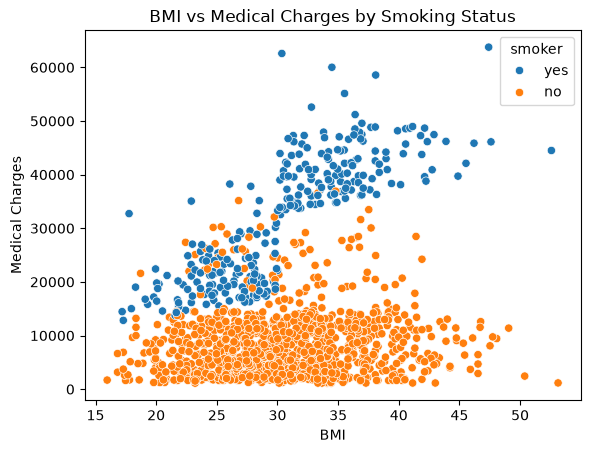

In [23]:
sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.xlabel("BMI")
plt.ylabel("Medical Charges")
plt.title("BMI vs Medical Charges by Smoking Status")

plt.show()

In [24]:
df.corr(numeric_only=True)

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


In [29]:
X = df[["age", "sex", "bmi", "children", "smoker", "region"]]

y = df[["charges"]]

In [30]:
X.head()

,age,sex,bmi,children,smoker,region
0,19,female,27.900,0,yes,southwest
1,18,male,33.770,1,no,southeast
2,28,male,33.000,3,no,southeast
3,33,male,22.705,0,no,northwest
4,32,male,28.880,0,no,northwest


In [31]:
y.head()

,charges
0,16884.92400
1,1725.55230
2,4449.46200
3,21984.47061
4,3866.85520


In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

In [35]:
df["smoker"] = df["smoker"].replace({
    "no": 0,
    "yes": 1
})

In [36]:
df["smoker"].value_counts()

smoker
0    1064
1     274
Name: count, dtype: int64

In [37]:
df["sex"] = df["sex"].replace({
    "male": 0,
    "female": 1
})

In [38]:
df["sex"].value_counts()

sex
0    676
1    662
Name: count, dtype: int64

In [40]:
region_encoded = pd.get_dummies(df["region"])

In [41]:
region_encoded.head()

,northeast,northwest,southeast,southwest
0,False,False,False,True
1,False,False,True,False
2,False,False,True,False
3,False,True,False,False
4,False,True,False,False


In [ ]:
X = X.drop("region", axis=1)

In [51]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'northeast', 'northwest',
       'southeast', 'southwest'],
      dtype='str')

In [47]:
X = pd.concat([X, region_encoded], axis=1)

In [52]:
X.head()

,age,sex,bmi,children,smoker,northeast,northwest,southeast,southwest
0,19,female,27.900,0,yes,False,False,False,True
1,18,male,33.770,1,no,False,False,True,False
2,28,male,33.000,3,no,False,False,True,False
3,33,male,22.705,0,no,False,True,False,False
4,32,male,28.880,0,no,False,True,False,False


In [53]:
X.shape

(1338, 9)

In [54]:
X.dtypes

age            int64
sex              str
bmi          float64
children       int64
smoker           str
northeast       bool
northwest       bool
southeast       bool
southwest       bool
dtype: object

In [55]:
X["sex"] = X["sex"].replace({
    "male": 0,
    "female": 1
})

In [56]:
X["sex"].value_counts()

sex
0    676
1    662
Name: count, dtype: int64

In [57]:
X["smoker"] = X["smoker"].replace({
    "no": 0,
    "yes": 1
})

In [58]:
X["smoker"].value_counts()

smoker
0    1064
1     274
Name: count, dtype: int64

In [59]:
X.dtypes

age            int64
sex           object
bmi          float64
children       int64
smoker        object
northeast       bool
northwest       bool
southeast       bool
southwest       bool
dtype: object

In [60]:
y = df["charges"]

In [61]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [63]:
X_train.shape, X_test.shape

((1070, 9), (268, 9))

In [64]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [65]:
model.fit(X_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 256.98, 18.59, 337.09,..., 88.91,-198.28,-350.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['age','sex','bmi',...,'northwest','southeast','southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.241e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [66]:
y_pred = model.predict(X_test)

In [68]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test , y_pred)

In [69]:
mae

4181.1944737536405

In [70]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test , y_pred)

In [71]:
r2

0.7835929767120723

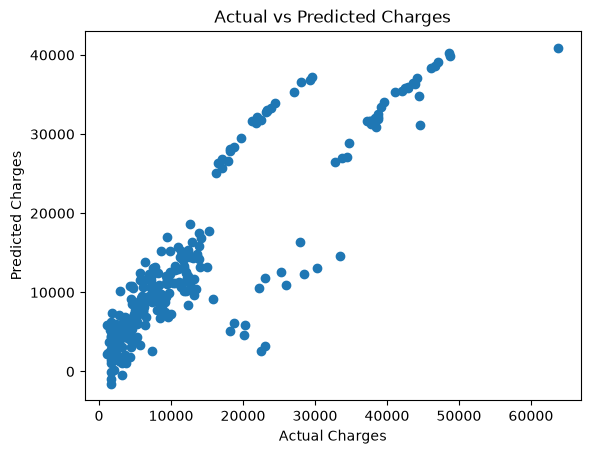

In [72]:
import matplotlib.pyplot as plt

plt.scatter(y_test , y_pred)
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.show()

In [73]:
X["bmi_smoker"] = X["bmi"] * X["smoker"]

In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [75]:
model_improved = LinearRegression()

In [76]:
model_improved.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 263.39, 525.23, 20.25,...,-259.4 ,-525.35,1470.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'southeast','southwest','bmi_smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3275
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [77]:
y_pred_improved = model_improved.predict(X_test)

In [78]:
mae_improved = mean_absolute_error(y_test, y_pred_improved)
mae_improved

2756.898659517963

In [79]:
r2_improved = r2_score(y_test, y_pred_improved)
r2_improved

0.8652503208873077

In [80]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_improved
})

comparison.head(10)

,Actual,Predicted
0,9095.06825,11248.036679
1,5272.17580,7416.914517
2,29330.98315,33065.596077
3,9301.89355,10829.975615
4,33750.29180,28195.542899
5,4536.25900,6487.375193
6,2117.33885,2787.291815
7,14210.53595,14426.298485
8,3732.62510,5683.413431
9,10264.44210,11679.786045


In [81]:
from sklearn.metrics import mean_squared_error

rmse = mean_squared_error(y_test, y_pred_improved) ** 0.5
rmse

4573.807686290385

In [82]:
model_improved.coef_

array([ 2.63390620e+02,  5.25230854e+02,  2.02507878e+01,  4.63652623e+02,
       -2.12069088e+04,  7.08080815e+02,  7.66644130e+01, -2.59399640e+02,
       -5.25345587e+02,  1.47086253e+03])

In [83]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model_improved.coef_
})

coefficients

,Feature,Coefficient
0,age,263.390620
1,sex,525.230854
2,bmi,20.250788
3,children,463.652623
4,smoker,-21206.908812
5,northeast,708.080815
6,northwest,76.664413
7,southeast,-259.399640
8,southwest,-525.345587
9,bmi_smoker,1470.862534


In [84]:
model_improved.intercept_

np.float64(-3274.9717183498087)

In [85]:
results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Baseline": [mae, None, r2],
    "Improved": [mae_improved, rmse, r2_improved]
})

results

,Metric,Baseline,Improved
0,MAE,4181.194474,2756.898660
1,RMSE,NaN,4573.807686
2,R2,0.783593,0.865250


In [86]:
residuals = y_test - y_pred_improved

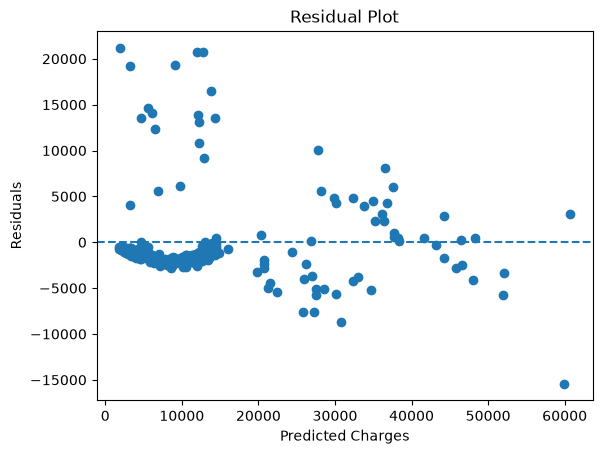

In [87]:
plt.scatter(y_pred_improved, residuals)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

In [88]:
X["age_smoker"] = X["age"] * X["smoker"]

In [89]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [90]:
model_v2 = LinearRegression()

In [92]:
model_v2.fit(X_train , y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 262.98, 525.6 , 20.4 ,...,-524.4 ,1470.48, 1.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['age','sex','bmi',...,'southwest','bmi_smoker','age_smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3263
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [95]:
y_pred_v2 = model_v2.predict(X_test)

In [96]:
mae_v2 = mean_absolute_error(y_test, y_pred_v2)
mae_v2

2757.7592042501374

In [97]:
X = X.drop("age_smoker", axis=1)

In [98]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'northeast', 'northwest',
       'southeast', 'southwest', 'bmi_smoker'],
      dtype='str')

In [99]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [100]:
final_model = LinearRegression()

In [101]:
final_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 263.39, 525.23, 20.25,...,-259.4 ,-525.35,1470.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'southeast','southwest','bmi_smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3275
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [102]:
y_pred_final = final_model.predict(X_test)

In [103]:
from sklearn.metrics import mean_absolute_error

final_mae = mean_absolute_error(y_test, y_pred_final)

print("Final MAE:", final_mae)

Final MAE: 2756.898659517963


In [104]:
from sklearn.metrics import r2_score

final_r2 = r2_score(y_test, y_pred_final)

print("Final R²:", final_r2)

Final R²: 0.8652503208873077


In [105]:
from sklearn.metrics import mean_squared_error

final_rmse = mean_squared_error(y_test, y_pred_final) ** 0.5

print("Final RMSE:", final_rmse)

Final RMSE: 4573.807686290385


In [106]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Baseline": [mae, None, r2],
    "Final Model": [final_mae, final_rmse, final_r2]
})

comparison

,Metric,Baseline,Final Model
0,MAE,4181.194474,2756.898660
1,RMSE,NaN,4573.807686
2,R²,0.783593,0.865250


In [107]:
mae_reduction = mae - final_mae
improvement_percent = (mae_reduction / mae) * 100

print("MAE Reduction:", mae_reduction)
print("Improvement:", improvement_percent, "%")

MAE Reduction: 1424.2958142356774
Improvement: 34.06432834388172 %


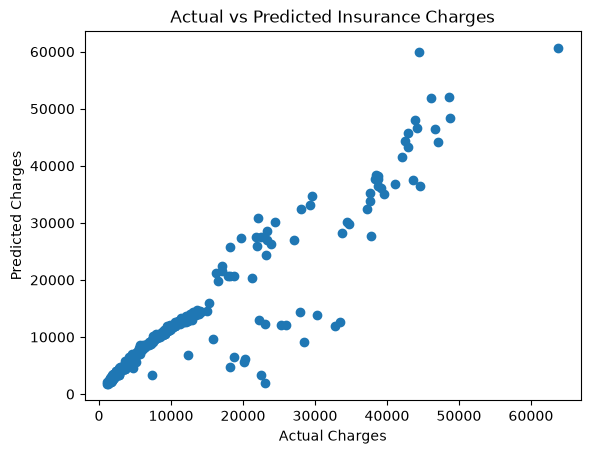

In [108]:
plt.scatter(y_test, y_pred_final)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()

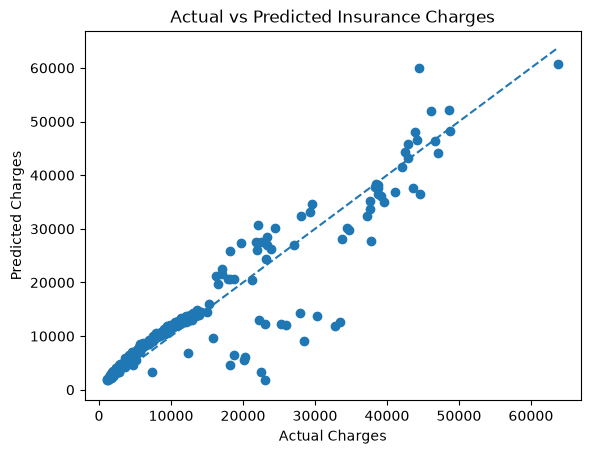

In [109]:
plt.scatter(y_test, y_pred_final)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()

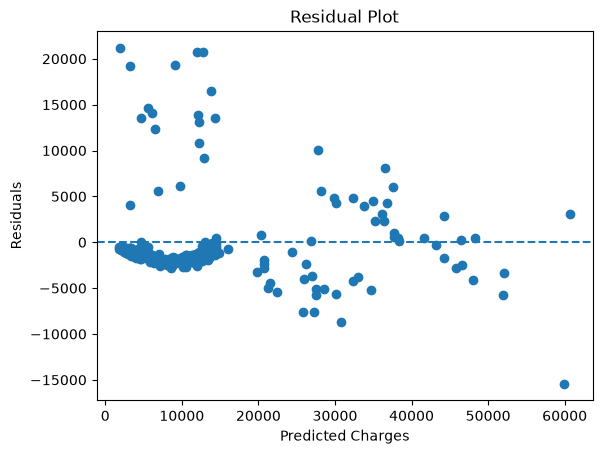

In [110]:
residuals_final = y_test - y_pred_final

plt.scatter(y_pred_final, residuals_final)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [111]:
print("Final Model Performance")
print("-----------------------")
print("MAE :", final_mae)
print("RMSE:", final_rmse)
print("R²  :", final_r2)

Final Model Performance
-----------------------
MAE : 2756.898659517963
RMSE: 4573.807686290385
R²  : 0.8652503208873077


In [112]:
new_patient = pd.DataFrame([{
    "age": 35,
    "sex": 0,
    "bmi": 28.5,
    "children": 1,
    "smoker": 1,
    "northeast": False,
    "northwest": False,
    "southeast": True,
    "southwest": False,
    "bmi_smoker": 28.5 * 1
}])

In [114]:
new_prediction = final_model.predict(new_patient)
print(f"Estimated Annual Insurance Charge: ${new_prediction[0]:,.2f}")

Estimated Annual Insurance Charge: $27,437.77


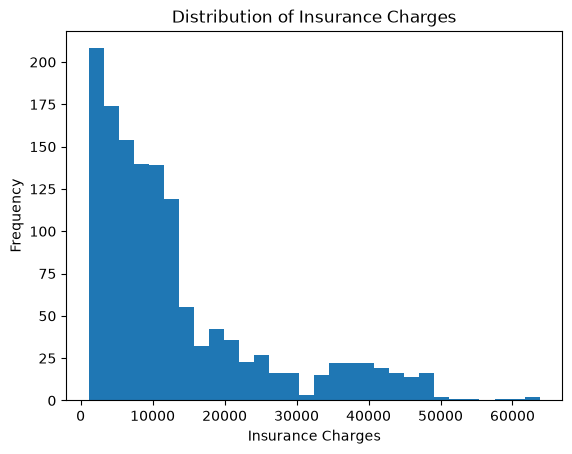

In [115]:
plt.hist(y, bins=30)

plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Insurance Charges")

plt.show()

In [122]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [123]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)

In [124]:
X_train_poly = poly.fit_transform(X_train)

In [125]:
X_test_poly = poly.transform(X_test)

In [126]:
poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](65,)","[ -22.06, 720.94, 193.6 ,...,-235.81, 187.72, -9.47]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1685
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,65
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(43)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](65,)","[40105.74,25746.31,13961.91,..., 0. , 0. , 0. ]"


In [127]:
y_pred_poly = poly_model.predict(X_test_poly)

In [128]:
poly_mae = mean_absolute_error(y_test, y_pred_poly)

print("Polynomial Model MAE:", poly_mae)

Polynomial Model MAE: 2738.408740464213


In [129]:
poly_r2 = r2_score(y_test, y_pred_poly)

print("Polynomial Model R²:", poly_r2)

Polynomial Model R²: 0.8573261247594215


In [130]:
poly_rmse = mean_squared_error(y_test, y_pred_poly) ** 0.5

print("Polynomial Model RMSE:", poly_rmse)

Polynomial Model RMSE: 4706.372079225714


In [131]:
residual_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_final,
    "Residual": y_test - y_pred_final
})

residual_df["Smoker"] = X_test["smoker"].values

residual_df.groupby("Smoker")["Residual"].mean()

Smoker
0   -261.524896
1   -662.769111
Name: Residual, dtype: float64

In [132]:
residual_df.groupby("Smoker")["Residual"].agg(["mean", "std"])

,mean,std
Smoker,,
0,-261.524896,4304.499618
1,-662.769111,5531.233088


In [133]:
X["bmi_squared"] = X["bmi"] ** 2

In [134]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [135]:
bmi_model = LinearRegression()

bmi_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 261.25, 507.99, 558.37,...,-541.37,1464.63, -8.57]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['age','sex','bmi',...,'southwest','bmi_smoker','bmi_squared']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.132e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [136]:
y_pred_bmi = bmi_model.predict(X_test)

In [137]:
mae_bmi = mean_absolute_error(y_test, y_pred_bmi)

mae_bmi

2732.0966617849103

In [138]:
r2_bmi = r2_score(y_test, y_pred_bmi)

r2_bmi

0.8670841399515511

In [139]:
rmse_bmi = mean_squared_error(y_test, y_pred_bmi) ** 0.5

rmse_bmi

4542.578416236729

In [161]:
print("Final Model Performance")
print("-----------------------")
print("MAE :", mae_bmi)
print("RMSE:", rmse_bmi)
print("R²  :", r2_bmi)

Final Model Performance
-----------------------
MAE : 2732.0966617849103
RMSE: 4542.578416236729
R²  : 0.8670841399515511


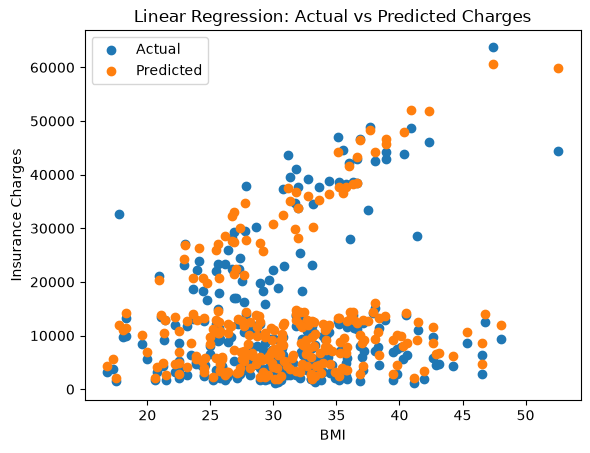

In [149]:
import matplotlib.pyplot as plt

plt.scatter(X_test["bmi"], y_test, label="Actual")
plt.scatter(X_test["bmi"], y_pred_final, label="Predicted")

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("Linear Regression: Actual vs Predicted Charges")
plt.legend()
plt.show()

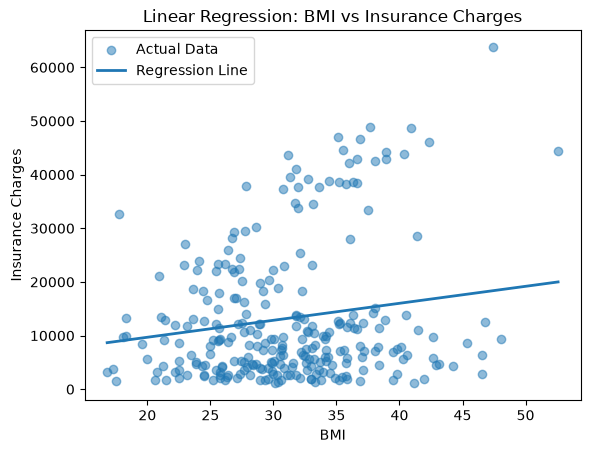

In [152]:
# Plot actual points
plt.scatter(
    X_test["bmi"],
    y_test,
    alpha=0.5,
    label="Actual Data"
)

# Plot regression line
plt.plot(
    bmi_range,
    line_predictions,
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.title("Linear Regression: BMI vs Insurance Charges")
plt.legend()
plt.show()

In [157]:
new_patient = pd.DataFrame([{
    "age": 35,
    "sex": 1,
    "bmi": 28.5,
    "children": 1,
    "smoker": 1,
    "northeast": False,
    "northwest": False,
    "southeast": True,
    "southwest": False,
    "bmi_smoker": 28.5
}])

new_patient

,age,sex,bmi,children,smoker,northeast,northwest,southeast,southwest,bmi_smoker
0,35,1,28.5,1,1,False,False,True,False,28.5


In [159]:
prediction = final_model.predict(new_patient)

print(f"Predicted Insurance Charge: ${prediction[0]:,.2f}")

Predicted Insurance Charge: $27,963.00


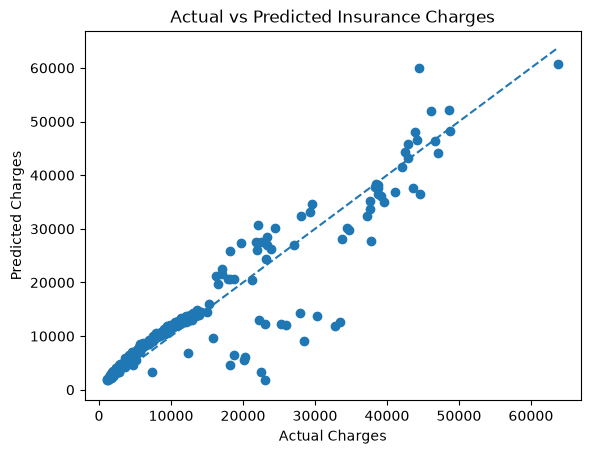

In [164]:
plt.scatter(y_test, y_pred_final)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.show()